# Housing Prices and Employment Earnings in Macao
## Final descriptive analysis
CISC7204 Data Science and Data Visualization · Class K · Team 04  
Academic year 2026–2027, Semester 1 · Release: 4 November 2026

Huang Rencong · Oscar Carranza Jimenez · Wang Xiuting · Wu Qi · Zhu Lingjing · Zhang Jingyi

**Question:** How did residential property prices change compared with the median monthly employment earnings of employed residents?

We use 13 published annual observations for each series, covering 2013–2025. The results are nominal and descriptive. The same source checks, calculations and charts can be repeated from the saved files.

## 1. Sources, population and units
The price series is DSEC's overall Macao Residential Property Price Index, with official base 2011=100. It measures changes in property prices; it is not the purchase price of a particular home.

The earnings series is the annual median monthly employment earnings of employed residents, in MOP. The Employment Survey covers local residents aged 16 and above within its residential survey coverage, including eligible employees, employers and self-employed people. Gross employment earnings include income from all jobs and, where applicable, business profits. The series excludes non-resident workers. It is not household income or the earnings of a fixed panel of people.

The survey excludes collective living quarters and people who work in Macao while living outside its coverage. The 2025 explanatory notes give these definitions on pages 32–34. The observation here is one calendar year, not one individual.

`rppi_annual.csv` and `resident_earnings_annual.csv` are separate source tables. `observation_provenance.csv` records the publication and exact location of all 26 values. `source_register.csv` contains 18 source records with URLs and SHA256 hashes.

In [1]:
from pathlib import Path
import sys
import platform
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

folder = Path.cwd()
assert (folder / "annual_inputs.csv").is_file()
figures = folder / "figures"
figures.mkdir(exist_ok=True)
print("Python", platform.python_version())
print("pandas", pd.__version__, "| Matplotlib", matplotlib.__version__)
print("Runtime:", sys.executable)

from pathlib import Path
import os, sys, json, base64, hashlib, ctypes, platform, copy
import pandas as pd
import plotly
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image, display

folder = Path.cwd()
figures = folder / 'figures'
figures.mkdir(exist_ok=True)
fonts = folder / 'assets' / 'fonts'
purple, teal, ink, muted, grid = '#6842B8', '#147D82', '#172127', '#53616A', '#EEF0F2'
body_font, title_font = 'IBM Plex Sans', 'IBM Plex Sans Condensed'
if not os.environ.get('BROWSER_PATH'):
    cached = Path.home() / 'Library/Caches/ms-playwright/chromium_headless_shell-1234/chrome-headless-shell-mac-arm64/chrome-headless-shell'
    if cached.is_file(): os.environ['BROWSER_PATH'] = str(cached)



Matplotlib is building the font cache; this may take a moment.


Python 3.12.14
pandas 3.0.5 | Matplotlib 3.11.1
Runtime: /Users/oscar/Documents/UM/Semester 2026-2/CISC/DataVisualization/code/.venv/bin/python


In [2]:
prices = pd.read_csv(folder / "rppi_annual.csv")
earnings = pd.read_csv(folder / "resident_earnings_annual.csv")
assert prices["year"].is_unique and earnings["year"].is_unique
joined = prices.merge(earnings, on="year", how="outer", validate="one_to_one", indicator=True)
assert joined["_merge"].eq("both").all()
columns = ["year", "rppi_2011_100", "resident_earnings_mop", "rppi_source_file", "earnings_source_file"]
data = joined[columns].sort_values("year").reset_index(drop=True)
data.to_csv(folder / "annual_inputs.csv", index=False)
provenance = pd.read_csv(folder / "observation_provenance.csv")
sources = pd.read_csv(folder / "source_register.csv")
assert len(provenance) == 26 and provenance["frequency"].eq("annual").all()
for source in sources.itertuples(index=False):
    raw = folder / "raw_sources" / source.source_file
    assert hashlib.sha256(raw.read_bytes()).hexdigest() == source.sha256
print("Two separate annual inputs joined one-to-one; all saved source hashes match.")
display(data[["year", "rppi_2011_100", "resident_earnings_mop"]])

Two separate annual inputs joined one-to-one; all saved source hashes match.


,year,rppi_2011_100,resident_earnings_mop
0,2013,188.0,15000
1,2014,241.1,15000
2,2015,227.0,18000
3,2016,219.3,18000
4,2017,244.8,19000
5,2018,265.5,20000
6,2019,266.8,20000
7,2020,267.0,20000
8,2021,266.8,20000
9,2022,254.0,19000


## 2. Current-vintage and quality checks
The saved publications were checked against DSEC's current public database on 4 November 2026. Indicator 65050 is overall RPPI for Macao; indicator 55057 is the total employed-resident earnings median. The saved read-only request specifies YEARLY, value type VAL and 2013–2025. All 26 annual observations match exactly. The raw response and request are preserved.

The 2025 Statistical Yearbook, Table 12.16, separately confirms the RPPI values for 2015, 2020 and 2023–2025. The 2025 Employment Survey confirms MOP 20,500 for both 2024 and 2025. Overlapping 2014–2016 RPPI values also agree in the 2016 and 2019 historical workbooks.

DSEC changed the pricing-model reference period to three consecutive months from 2017 and revised indices from 2017. The original 2017 release reported 252.8; the later historical table and current database report **244.8**, which we use. The official base remains 2011=100. This verifies the current published values, while the model change remains a comparability limitation. We therefore also report 2018–2025, which avoids the 2017 transition. We do not create our own backcast or adjustment.

In [3]:
current = json.loads((folder / "raw_sources" / "current_annual_series_2026-11-04.json").read_text())
assert current["Status"] == "OK"
assert {row["indicatorId"] for row in current["Value"]} == {65050, 55057}
checks = []
for series in current["Value"]:
    indicator = series["indicatorId"]
    assert indicator in [65050, 55057]
    column = "rppi_2011_100" if indicator == 65050 else "resident_earnings_mop"
    assert sorted(row["Year"] for row in series["dsecIndicatorData"]) == list(range(2013, 2026))
    for row in series["dsecIndicatorData"]:
        assert row["PeriodID"] is None and row["ReferencePeriod"] == str(row["Year"])
        assert row["type"] == "VAL"
        published = data.loc[data["year"].eq(row["Year"]), column].item()
        assert published == row["IndicatorValue"]
        checks.append([row["Year"], indicator, published, row["IndicatorValue"], row["LastUpdateDate"]])
assert len(checks) == 26
print("26 of 26 published annual observations exactly match the current DSEC database.")
display(pd.DataFrame(checks, columns=["year", "indicator_id", "published", "current", "database_last_update"]))

26 of 26 published annual observations exactly match the current DSEC database.


,year,indicator_id,published,current,database_last_update
0,2013,65050,188.0,188.0,2018-05-24T09:02:20.817
1,2014,65050,241.1,241.1,2018-05-24T09:02:22.123
2,2015,65050,227.0,227.0,2018-05-24T09:02:23.343
3,2016,65050,219.3,219.3,2018-05-24T09:02:24.523
4,2017,65050,244.8,244.8,2018-05-24T09:02:25.763
5,2018,65050,265.5,265.5,2019-02-08T10:51:43.94
6,2019,65050,266.8,266.8,2020-02-07T11:45:29.857
7,2020,65050,267.0,267.0,2021-02-08T11:39:15.277
8,2021,65050,266.8,266.8,2022-02-08T10:28:19.42
9,2022,65050,254.0,254.0,2023-02-08T11:15:51.397


In [4]:
data = data.sort_values("year").reset_index(drop=True)
assert data["year"].tolist() == list(range(2013, 2026))
assert not data["year"].duplicated().any()
assert data[["rppi_2011_100", "resident_earnings_mop"]].notna().all().all()
assert data[["rppi_2011_100", "resident_earnings_mop"]].gt(0).all().all()
assert data.loc[data["year"].eq(2017), "rppi_2011_100"].item() == 244.8
print("13 common annual years; no missing values, duplicate years or nonpositive levels.")
display(data[["rppi_2011_100", "resident_earnings_mop"]].describe().round(2))

13 common annual years; no missing values, duplicate years or nonpositive levels.


,rppi_2011_100,resident_earnings_mop
count,13.00,13.00
mean,238.15,18846.15
std,27.20,1897.20
min,188.00,15000.00
25%,219.30,18000.00
50%,244.40,20000.00
75%,265.50,20000.00
max,267.00,20500.00


## 3. Measures
Use 2013, the first common year, as 100 for both series:

- Price index = 100 × RPPI(t) / RPPI(2013).
- Earnings index = 100 × earnings(t) / earnings(2013).
- Annual growth = 100 × [X(t) / X(t−1) − 1], only for consecutive years.
- Relative pressure = 100 × price index / earnings index.

Relative pressure below 100 means prices gained less than earnings since that base year. It does not show whether a household can buy a home. The first growth observation is missing because 2012 is outside the selected input. No gap is interpolated, and quarterly medians are never averaged to construct annual medians.

In [5]:
base_year = int(data["year"].iloc[0])
data["price_index_2013_100"] = 100 * data["rppi_2011_100"] / data["rppi_2011_100"].iloc[0]
data["earnings_index_2013_100"] = 100 * data["resident_earnings_mop"] / data["resident_earnings_mop"].iloc[0]
consecutive = data["year"].diff().eq(1)
data["rppi_growth_pct"] = (100 * data["rppi_2011_100"].pct_change(fill_method=None)).where(consecutive)
data["earnings_growth_pct"] = (100 * data["resident_earnings_mop"].pct_change(fill_method=None)).where(consecutive)
data["relative_pressure_2013_100"] = 100 * data["price_index_2013_100"] / data["earnings_index_2013_100"]
assert np.allclose(data.loc[0, ["price_index_2013_100", "earnings_index_2013_100", "relative_pressure_2013_100"]].astype(float), 100)
assert data["rppi_growth_pct"].isna().sum() == 1
assert data["earnings_growth_pct"].isna().sum() == 1
data.to_csv(folder / "annual_analysis.csv", index=False, float_format="%.10f")
display(data[["year", "price_index_2013_100", "earnings_index_2013_100", "rppi_growth_pct", "earnings_growth_pct", "relative_pressure_2013_100"]].round(2))

,year,price_index_2013_100,earnings_index_2013_100,rppi_growth_pct,earnings_growth_pct,relative_pressure_2013_100
0,2013,100.00,100.00,NaN,NaN,100.00
1,2014,128.24,100.00,28.24,0.00,128.24
2,2015,120.74,120.00,-5.85,20.00,100.62
3,2016,116.65,120.00,-3.39,0.00,97.21
4,2017,130.21,126.67,11.63,5.56,102.80
5,2018,141.22,133.33,8.46,5.26,105.92
6,2019,141.91,133.33,0.49,0.00,106.44
7,2020,142.02,133.33,0.07,0.00,106.52
8,2021,141.91,133.33,-0.07,0.00,106.44
9,2022,135.11,126.67,-4.80,-5.00,106.66


### Figure rendering
The charts use the same calculations as the tables. Annual points are joined by straight lines. Line-chart axes start at 80 and 60, as stated beneath each chart; bar charts start at zero. Fonts are bundled under their open licence. PNG, PDF, SVG and local interactive versions are exported from the same specifications.

In [6]:
font_specs = [
 ('IBMPlexSans-Regular.ttf',body_font,400,'normal'),
 ('IBMPlexSans-Medium.ttf',body_font,500,'normal'),
 ('IBMPlexSans-SemiBold.ttf',body_font,600,'normal'),
 ('IBMPlexSans-Italic.ttf',body_font,400,'italic'),
 ('IBMPlexSansCondensed-Regular.ttf',title_font,400,'normal'),
 ('IBMPlexSansCondensed-Medium.ttf',title_font,500,'normal'),
 ('IBMPlexSansCondensed-SemiBold.ttf',title_font,600,'normal')]
font_css = ''
for file, family, weight, style in font_specs:
    encoded = base64.b64encode((fonts / file).read_bytes()).decode()
    font_css += f"@font-face{{font-family:'{family}';font-style:{style};font-weight:{weight};src:url(data:font/ttf;base64,{encoded}) format('truetype');}}\n"

if platform.system() == 'Darwin':
    cf = ctypes.CDLL('/System/Library/Frameworks/CoreFoundation.framework/CoreFoundation')
    ct = ctypes.CDLL('/System/Library/Frameworks/CoreText.framework/CoreText')
    cf.CFURLCreateFromFileSystemRepresentation.argtypes = [ctypes.c_void_p,ctypes.c_char_p,ctypes.c_long,ctypes.c_bool]
    cf.CFURLCreateFromFileSystemRepresentation.restype = ctypes.c_void_p
    cf.CFRelease.argtypes = [ctypes.c_void_p]
    cf.CFArrayGetCount.argtypes = [ctypes.c_void_p]; cf.CFArrayGetCount.restype = ctypes.c_long
    cf.CFArrayGetValueAtIndex.argtypes = [ctypes.c_void_p,ctypes.c_long]; cf.CFArrayGetValueAtIndex.restype = ctypes.c_void_p
    cf.CFStringGetCString.argtypes = [ctypes.c_void_p,ctypes.c_char_p,ctypes.c_long,ctypes.c_uint32]; cf.CFStringGetCString.restype = ctypes.c_bool
    ct.CTFontManagerCopyAvailablePostScriptNames.restype = ctypes.c_void_p
    ct.CTFontManagerRegisterFontsForURL.argtypes = [ctypes.c_void_p,ctypes.c_uint32,ctypes.POINTER(ctypes.c_void_p)]
    ct.CTFontManagerRegisterFontsForURL.restype = ctypes.c_bool
    ct.CTFontManagerUnregisterFontsForURL.argtypes = ct.CTFontManagerRegisterFontsForURL.argtypes
    ct.CTFontManagerUnregisterFontsForURL.restype = ctypes.c_bool

def plex_names():
    if platform.system() != 'Darwin': return []
    names = ct.CTFontManagerCopyAvailablePostScriptNames()
    found = []
    for index in range(cf.CFArrayGetCount(names)):
        value = cf.CFArrayGetValueAtIndex(names,index); buffer = ctypes.create_string_buffer(256)
        if cf.CFStringGetCString(value,buffer,256,0x08000100) and buffer.value.startswith(b'IBMPlex'):
            found.append(buffer.value.decode())
    cf.CFRelease(names)
    return sorted(found)



In [7]:

def chart_layout(fig, title, subtitle, x_range, y_range, y_ticks, x_ticks):
    fig.update_layout(template='none',width=1200,height=760,paper_bgcolor='white',plot_bgcolor='white',
        font=dict(family=body_font,size=18,color=ink),margin=dict(l=82,r=58,t=120,b=150),
        title=dict(text=title,x=0.068,y=0.96,xanchor='left',yanchor='top',
            font=dict(family=title_font,size=36,weight=600,color=ink),
            subtitle=dict(text=subtitle,font=dict(family=body_font,size=19,color=muted))),hovermode='x unified')
    fig.update_xaxes(range=x_range,tickvals=x_ticks,tickfont=dict(size=18),showgrid=False,zeroline=False,
        showline=True,linecolor='#B8C0C5',linewidth=1,ticks='')
    fig.update_yaxes(range=y_range,tickvals=y_ticks,tickfont=dict(size=18),showgrid=True,gridcolor=grid,
        gridwidth=1,zeroline=False,showline=False,ticks='')
    return fig

def source_footer(fig, first, second):
    for y, text in [(-0.19,first),(-0.245,second)]:
        fig.add_annotation(x=0,y=y,xref='paper',yref='paper',text=text,showarrow=False,xanchor='left',
            align='left',font=dict(family=body_font,size=14,color=muted),name='source-footer')



In [8]:
export_log = []
def export_chart(fig, stem, table, alt_text):
    report = go.Figure(fig)
    report.update_layout(height=620,margin=dict(l=90,r=100,t=110,b=140))
    report.update_xaxes(tickfont=dict(size=24))
    report.update_yaxes(tickfont=dict(size=24))
    report.layout.title.font.size = 34
    report.layout.title.subtitle.font.size = 22
    report.layout.legend.font.size = 21
    for annotation in report.layout.annotations:
        if annotation.name != 'source-footer':
            annotation.font.size = 20 if annotation.text in ['Near-flat, 2019–2021', '2013 relationship', '100 = unchanged'] else 24
    footer = [a for a in report.layout.annotations if a.name == 'source-footer']
    for annotation, y in zip(footer,[-0.22,-0.31]):
        annotation.y = y
        annotation.font.size = 20
        annotation.text = annotation.text.replace('Source: DSEC RPPI releases, Employment Survey 2013 and Economic Bulletin Table V.5.', 'Sources: DSEC RPPI releases; Employment Survey 2013; Economic Bulletin V.5.')
    before = plex_names(); owned = []
    try:
        if platform.system() == 'Darwin':
            for file, family, weight, style in font_specs:
                path = str(fonts/file).encode()
                url = cf.CFURLCreateFromFileSystemRepresentation(None,path,len(path),False)
                error = ctypes.c_void_p()
                if ct.CTFontManagerRegisterFontsForURL(url,3,ctypes.byref(error)): owned.append(url)
                else: cf.CFRelease(url)
        paths = [figures/f'{prefix}{stem}.{extension}' for prefix in ['', 'report_'] for extension in ['png','pdf','svg']]
        pio.write_images(fig=[fig]*3+[report]*3,file=paths,format=['png','pdf','svg']*2,
            width=[1200]*6,height=[760]*3+[620]*3,scale=[2,1,1]*2)
    finally:
        if platform.system() == 'Darwin':
            for url in owned:
                error = ctypes.c_void_p()
                assert ct.CTFontManagerUnregisterFontsForURL(url,3,ctypes.byref(error))
                cf.CFRelease(url)
            assert plex_names() == before
    for path in [figures/f'{stem}.svg', figures/f'report_{stem}.svg']:
        svg = path.read_text(); position = svg.find('>',svg.find('<svg'))+1
        svg = svg[:position]+'<defs><style><![CDATA['+font_css+']]></style></defs>'+svg[position:]
        path.write_text(svg)
    fig.write_json(figures/f'{stem}.plotly.json')
    html = fig.to_html(include_plotlyjs=True,include_mathjax=False,full_html=True,
        config=dict(displaylogo=False,responsive=True,scrollZoom=False,toImageButtonOptions=dict(format='svg',filename=stem)))
    style = font_css + "body{margin:0;color:#172127;background:white;font-family:'IBM Plex Sans',sans-serif}main{max-width:1200px;margin:auto;padding:0 28px 36px}.chart-scroll{overflow-x:auto}.plotly-graph-div{min-width:960px}table{border-collapse:collapse;width:100%;font-size:16px;font-variant-numeric:tabular-nums}th,td{text-align:right;padding:9px 12px;border-bottom:1px solid #EEF0F2}th:first-child,td:first-child{text-align:left}summary{cursor:pointer;padding:20px 0;font-weight:500}a:focus-visible,summary:focus-visible{outline:2px solid #6842B8;outline-offset:4px}::selection{background:#e4daf8;color:#172127}p{line-height:1.6}"
    html = html.replace('</head>','<style>'+style+'</style></head>')
    html = html.replace('<body>','<body><main><div class="chart-scroll" role="img" aria-label="'+alt_text+'">')
    html = html.replace('</body>','</div><p>'+alt_text+'</p><details><summary>Annual values</summary>'+table.to_html(index=False,border=0,float_format=lambda x:f'{x:.2f}')+'</details></main></body>')
    (figures/f'{stem}.html').write_text(html)
    export_log.append({'stem':stem,'standard_dimensions':[1200,760],'report_dimensions':[1200,620],
        'temporary_session_fonts_registered':len(owned),'session_fonts_restored':plex_names()==before,
        'svg_embedded_font_faces':7,'html_plotly_inlined':True,'html_mathjax_disabled':True})
    (folder/'visual_export_log.json').write_text(json.dumps(export_log,indent=2))
    display(Image(filename=str(figures/f'{stem}.png')))



## 4. Common-base trends
Prices and earnings do not follow a smooth path. A common axis and base show their relative changes without treating the original units as equal. Annual observations are marked; colour, marker and line style distinguish the series.

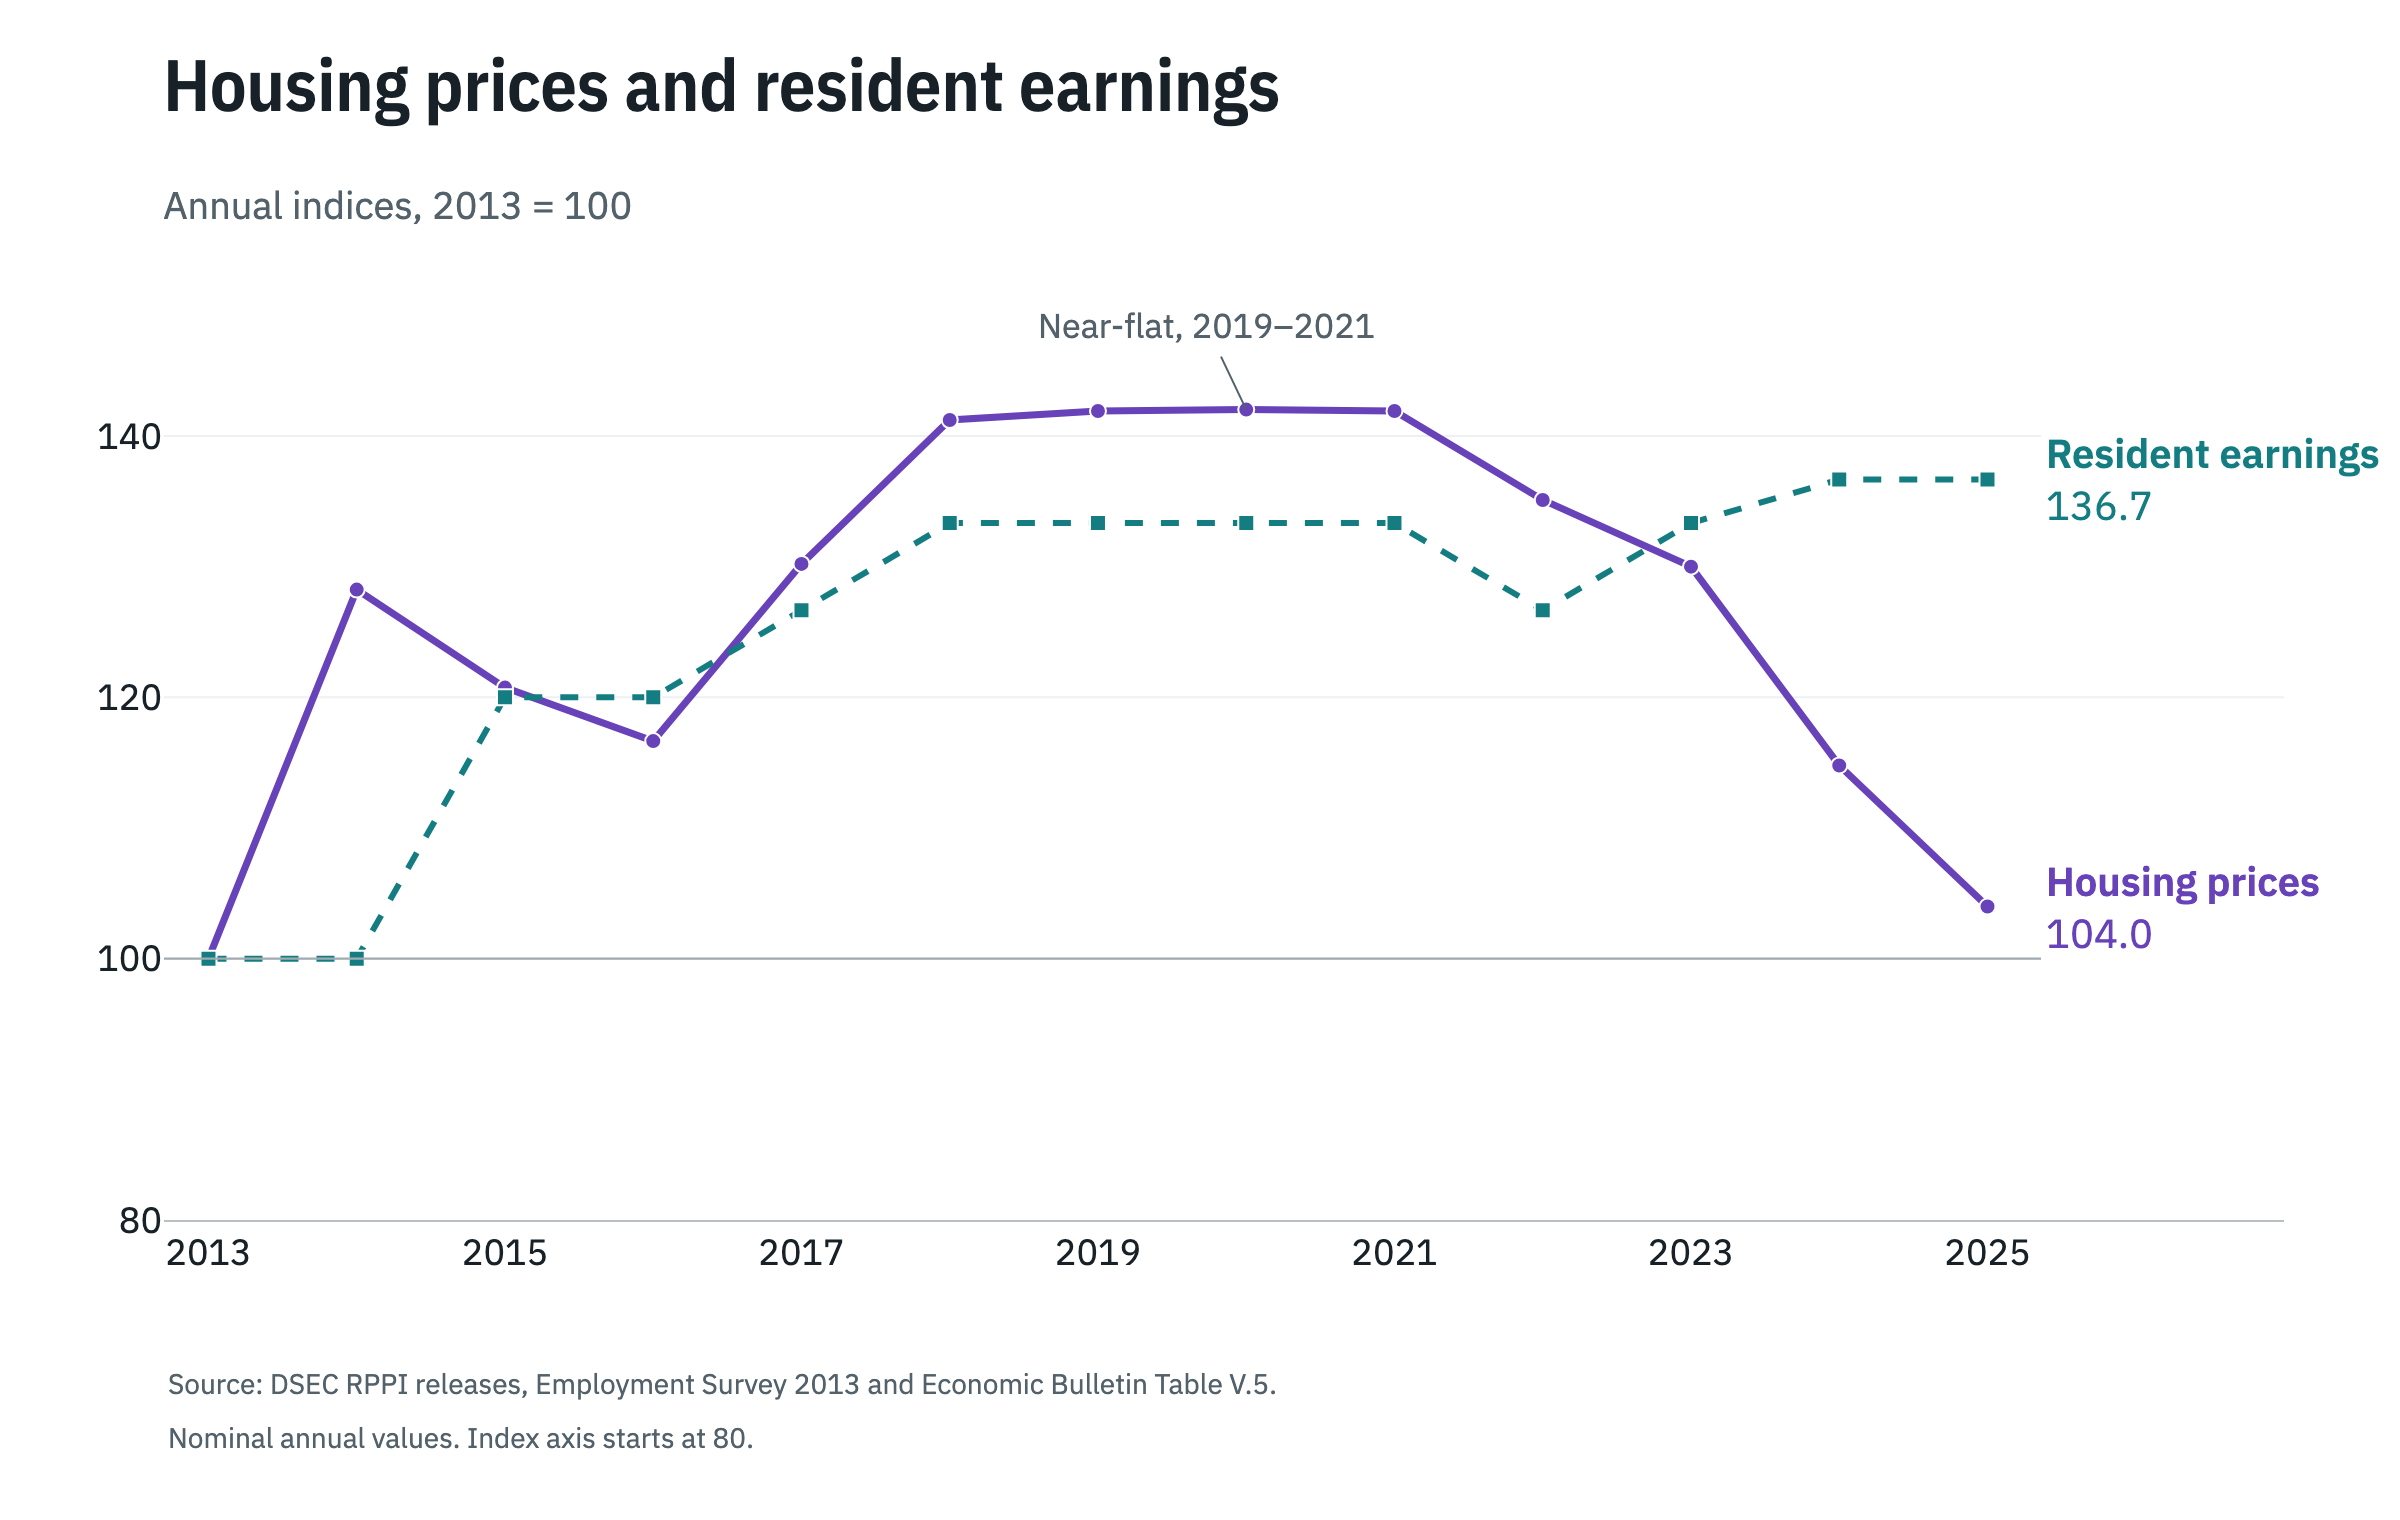

In [9]:
trend = go.Figure()
trend.add_trace(go.Scatter(x=data.year,y=data.price_index_2013_100,mode='lines+markers',name='Housing prices',
    line=dict(color=purple,width=3.5),marker=dict(color=purple,size=8,symbol='circle',line=dict(color='white',width=1)),
    hovertemplate='%{x}<br>Housing prices: %{y:.1f}<extra></extra>'))
trend.add_trace(go.Scatter(x=data.year,y=data.earnings_index_2013_100,mode='lines+markers',name='Resident earnings',
    line=dict(color=teal,width=3,dash='dash'),marker=dict(color=teal,size=8,symbol='square',line=dict(color='white',width=1)),
    hovertemplate='%{x}<br>Resident earnings: %{y:.1f}<extra></extra>'))
chart_layout(trend,'Housing prices and resident earnings','Annual indices, 2013 = 100',
    [2012.7,2027.0],[80,155],[80,100,120,140],[2013,2015,2017,2019,2021,2023,2025])
trend.update_layout(showlegend=False)
trend.add_hline(y=100,line_color='#A1ABB2',line_width=1.2)
for y, text, color in [(data.earnings_index_2013_100.iloc[-1],'<b>Resident earnings</b><br>136.7',teal),
                        (data.price_index_2013_100.iloc[-1],'<b>Housing prices</b><br>104.0',purple)]:
    trend.add_annotation(x=2025.35,y=float(y),text=text,showarrow=False,xanchor='left',align='left',bgcolor='white',borderpad=2,font=dict(family=body_font,size=20,color=color))
trend.add_annotation(x=2020,y=142.0212765957,text='Near-flat, 2019–2021',showarrow=True,arrowhead=0,
    arrowcolor=muted,arrowwidth=1,ax=-20,ay=-42,font=dict(family=body_font,size=17,color=muted),bgcolor='white',borderpad=4)
source_footer(trend,'Source: DSEC RPPI releases, Employment Survey 2013 and Economic Bulletin Table V.5.',
    'Nominal annual values. Index axis starts at 80.')
export_chart(trend,'01_common_base_trends',data[['year','rppi_2011_100','resident_earnings_mop','price_index_2013_100','earnings_index_2013_100']],
    'The price index ends at 104.0 and the resident earnings index at 136.7 in 2025, with 2013 equal to 100. Annual observations are joined by straight lines.')

## 5. Consecutive-year growth
The chart includes all observed annual changes, including large moves. Rates calculated from published rounded levels can differ slightly from DSEC's rounded published percentages. The largest price rise is 28.2% in 2014; the largest price fall is 11.7% in 2024. The resident earnings median rises 20.0% in 2015 and falls 5.0% in 2022. These are changes in aggregate medians, not pay changes experienced by every person.

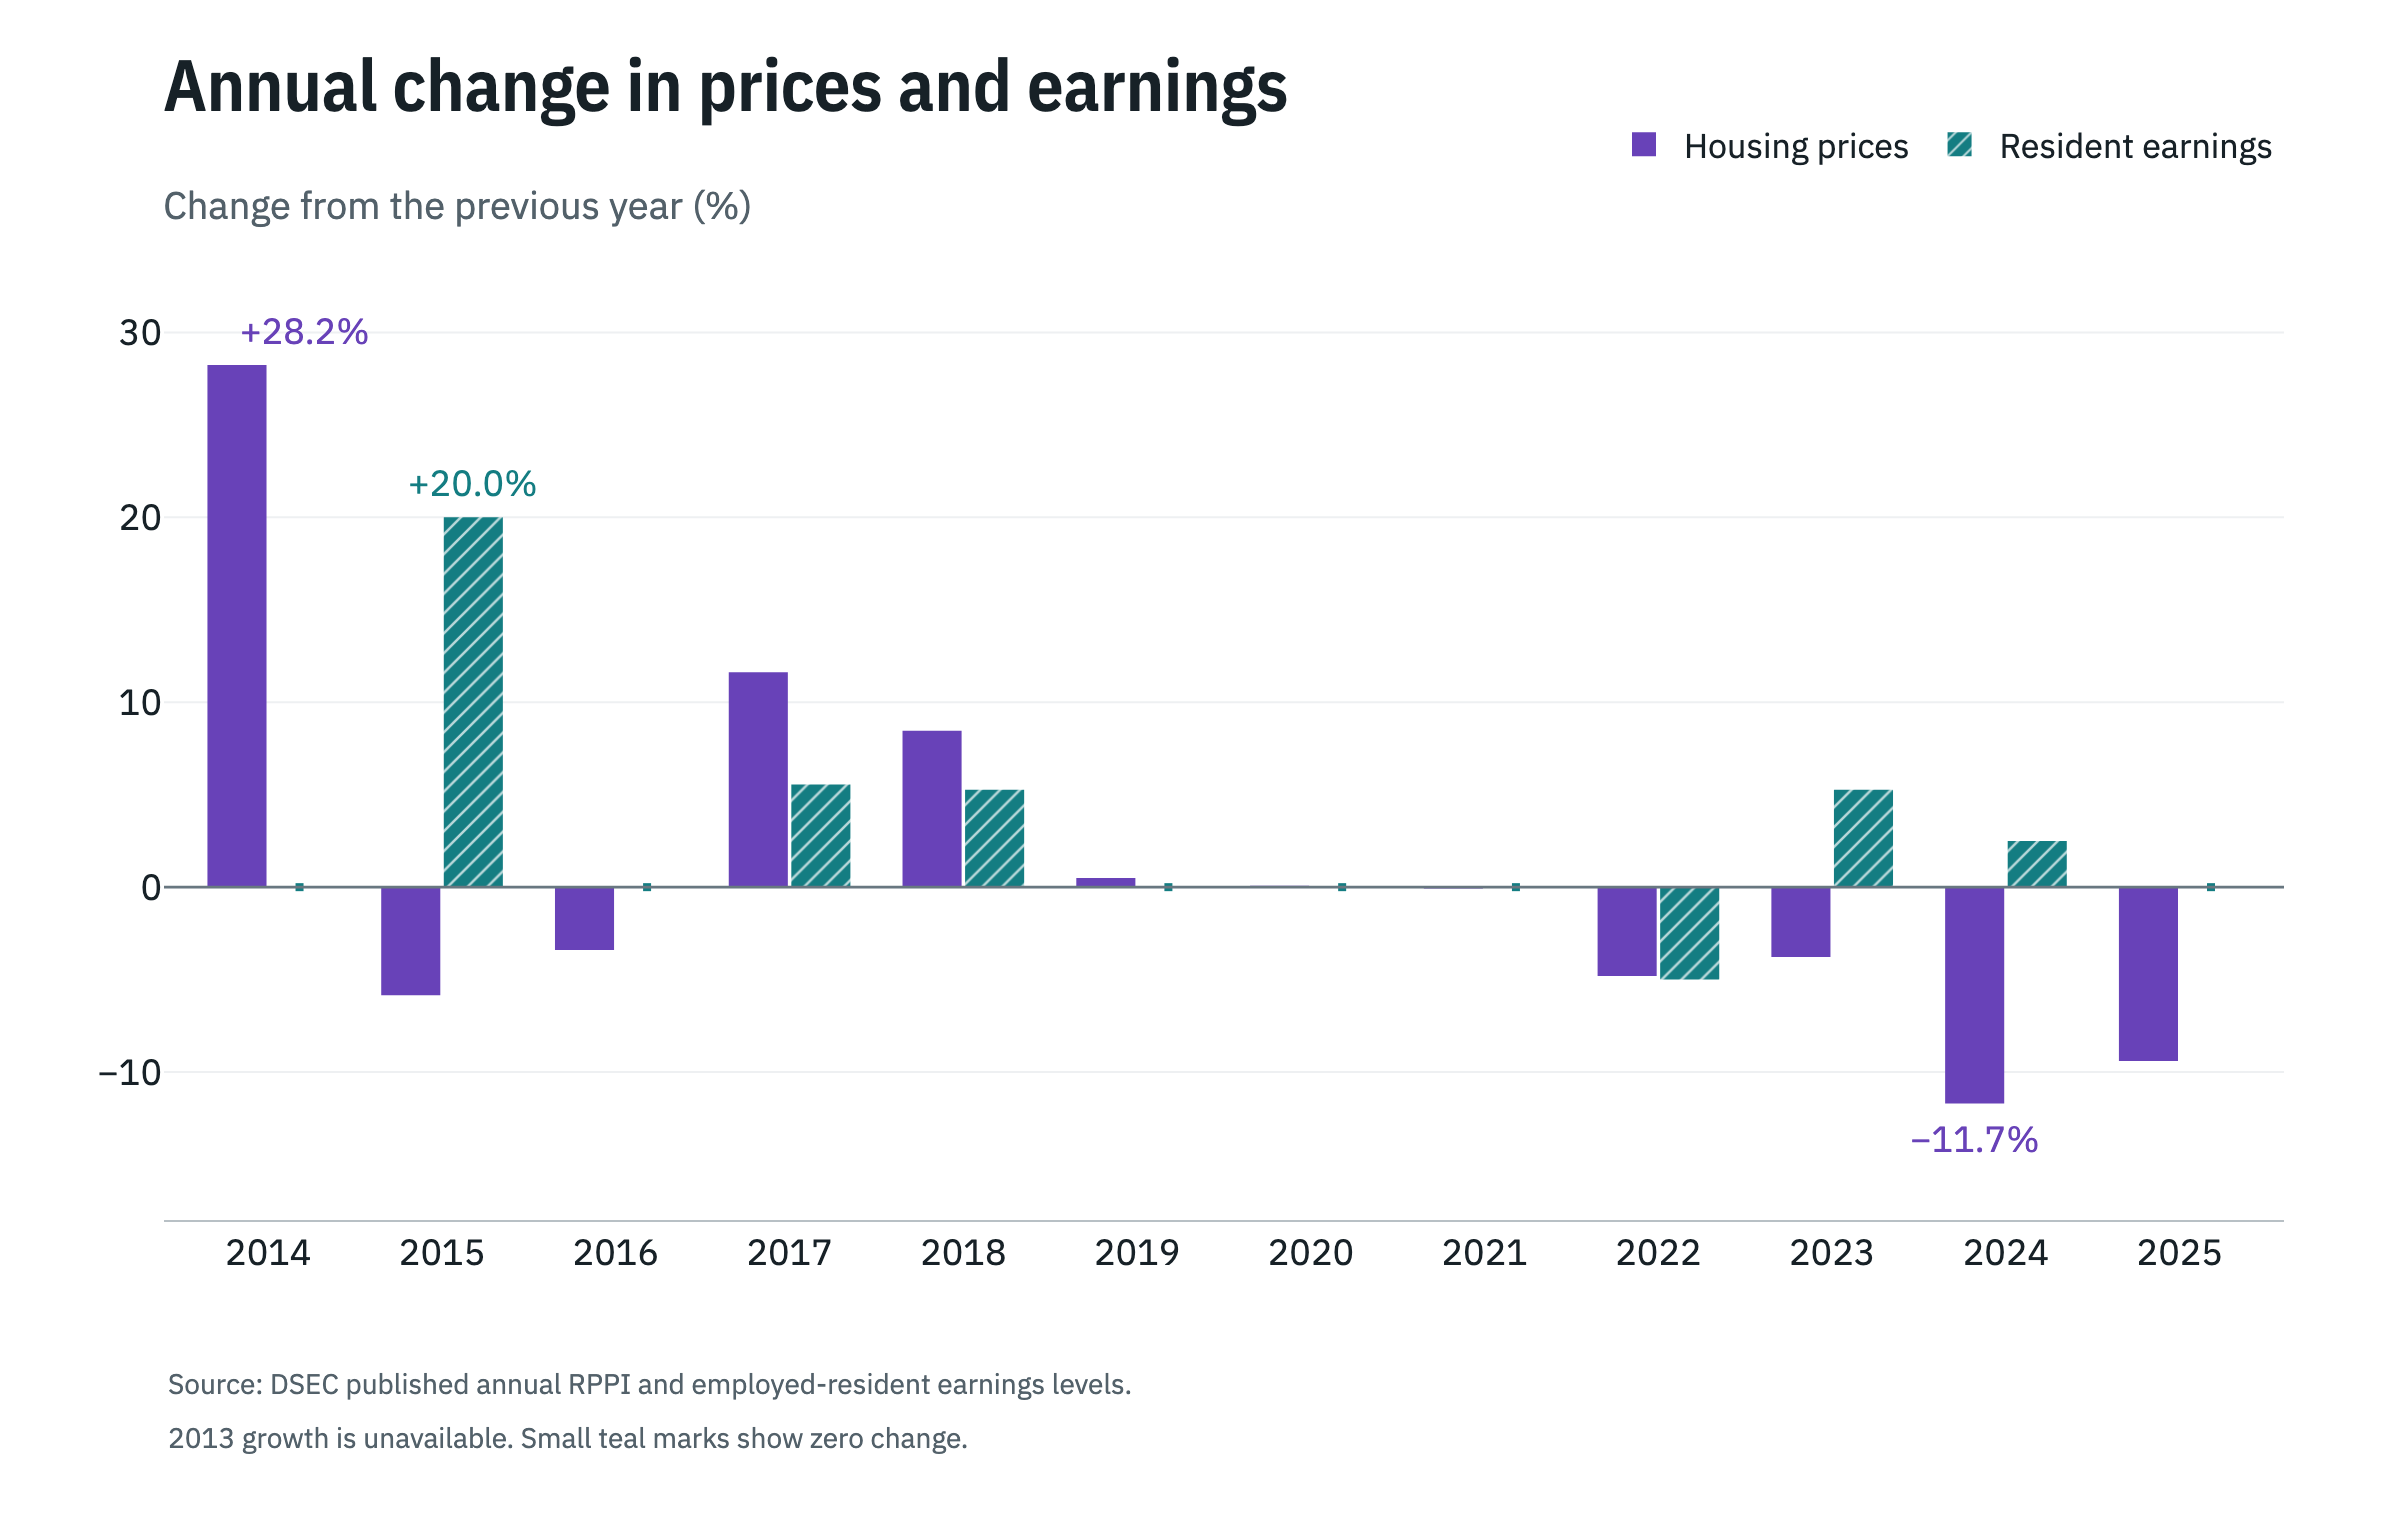

In [10]:
annual = data.loc[data.year.gt(2013)]
growth = go.Figure()
growth.add_trace(go.Bar(x=annual.year-0.18,y=annual.rppi_growth_pct,width=0.34,name='Housing prices',
    marker=dict(color=purple),customdata=annual.year,hovertemplate='%{customdata}<br>Housing prices: %{y:.2f}%<extra></extra>'))
growth.add_trace(go.Bar(x=annual.year+0.18,y=annual.earnings_growth_pct,width=0.34,name='Resident earnings',
    marker=dict(color=teal,pattern=dict(shape='/',bgcolor=teal,fillmode='overlay',fgcolor='white',fgopacity=0.7,size=7,solidity=0.18)),
    customdata=annual.year,hovertemplate='%{customdata}<br>Resident earnings: %{y:.2f}%<extra></extra>'))
zeros = annual.loc[annual.earnings_growth_pct.eq(0)]
growth.add_trace(go.Scatter(x=zeros.year+0.18,y=zeros.earnings_growth_pct,mode='markers',showlegend=False,
    marker=dict(color=teal,size=4,symbol='square'),hoverinfo='skip'))
chart_layout(growth,'Annual change in prices and earnings','Change from the previous year (%)',
    [2013.4,2025.6],[-18,35],[-10,0,10,20,30],list(range(2014,2026)))
growth.update_layout(barmode='overlay',legend=dict(orientation='h',x=1,y=1.06,xanchor='right',yanchor='bottom',font=dict(size=17)))
growth.add_hline(y=0,line_color='#687780',line_width=1.4)
for x,y,text,color,shift in [(2013.82,28.2446808511,'+28.2%',purple,17),(2015.18,20,'+20.0%',teal,17),(2023.82,-11.7021276596,'−11.7%',purple,-18)]:
    growth.add_annotation(x=x,y=y,text=text,showarrow=False,yshift=shift,xanchor='left' if x==2013.82 else 'center',font=dict(family=body_font,size=18,color=color))
source_footer(growth,'Source: DSEC published annual RPPI and employed-resident earnings levels.',
    '2013 growth is unavailable. Small teal marks show zero change.')
export_chart(growth,'02_annual_growth',annual[['year','rppi_growth_pct','earnings_growth_pct']],
    'Annual growth compares consecutive years. Prices rise most in 2014 and fall most in 2024. Teal hatched bars show resident earnings; small teal marks show zero change.')

## 6. Relative change in prices and earnings
The index compares changes since a stated year. It has no currency unit. In 2025 it is 76.1 with 2013=100. This is a relative change measure, not a dwelling-price-to-household-income or mortgage-payment ratio.

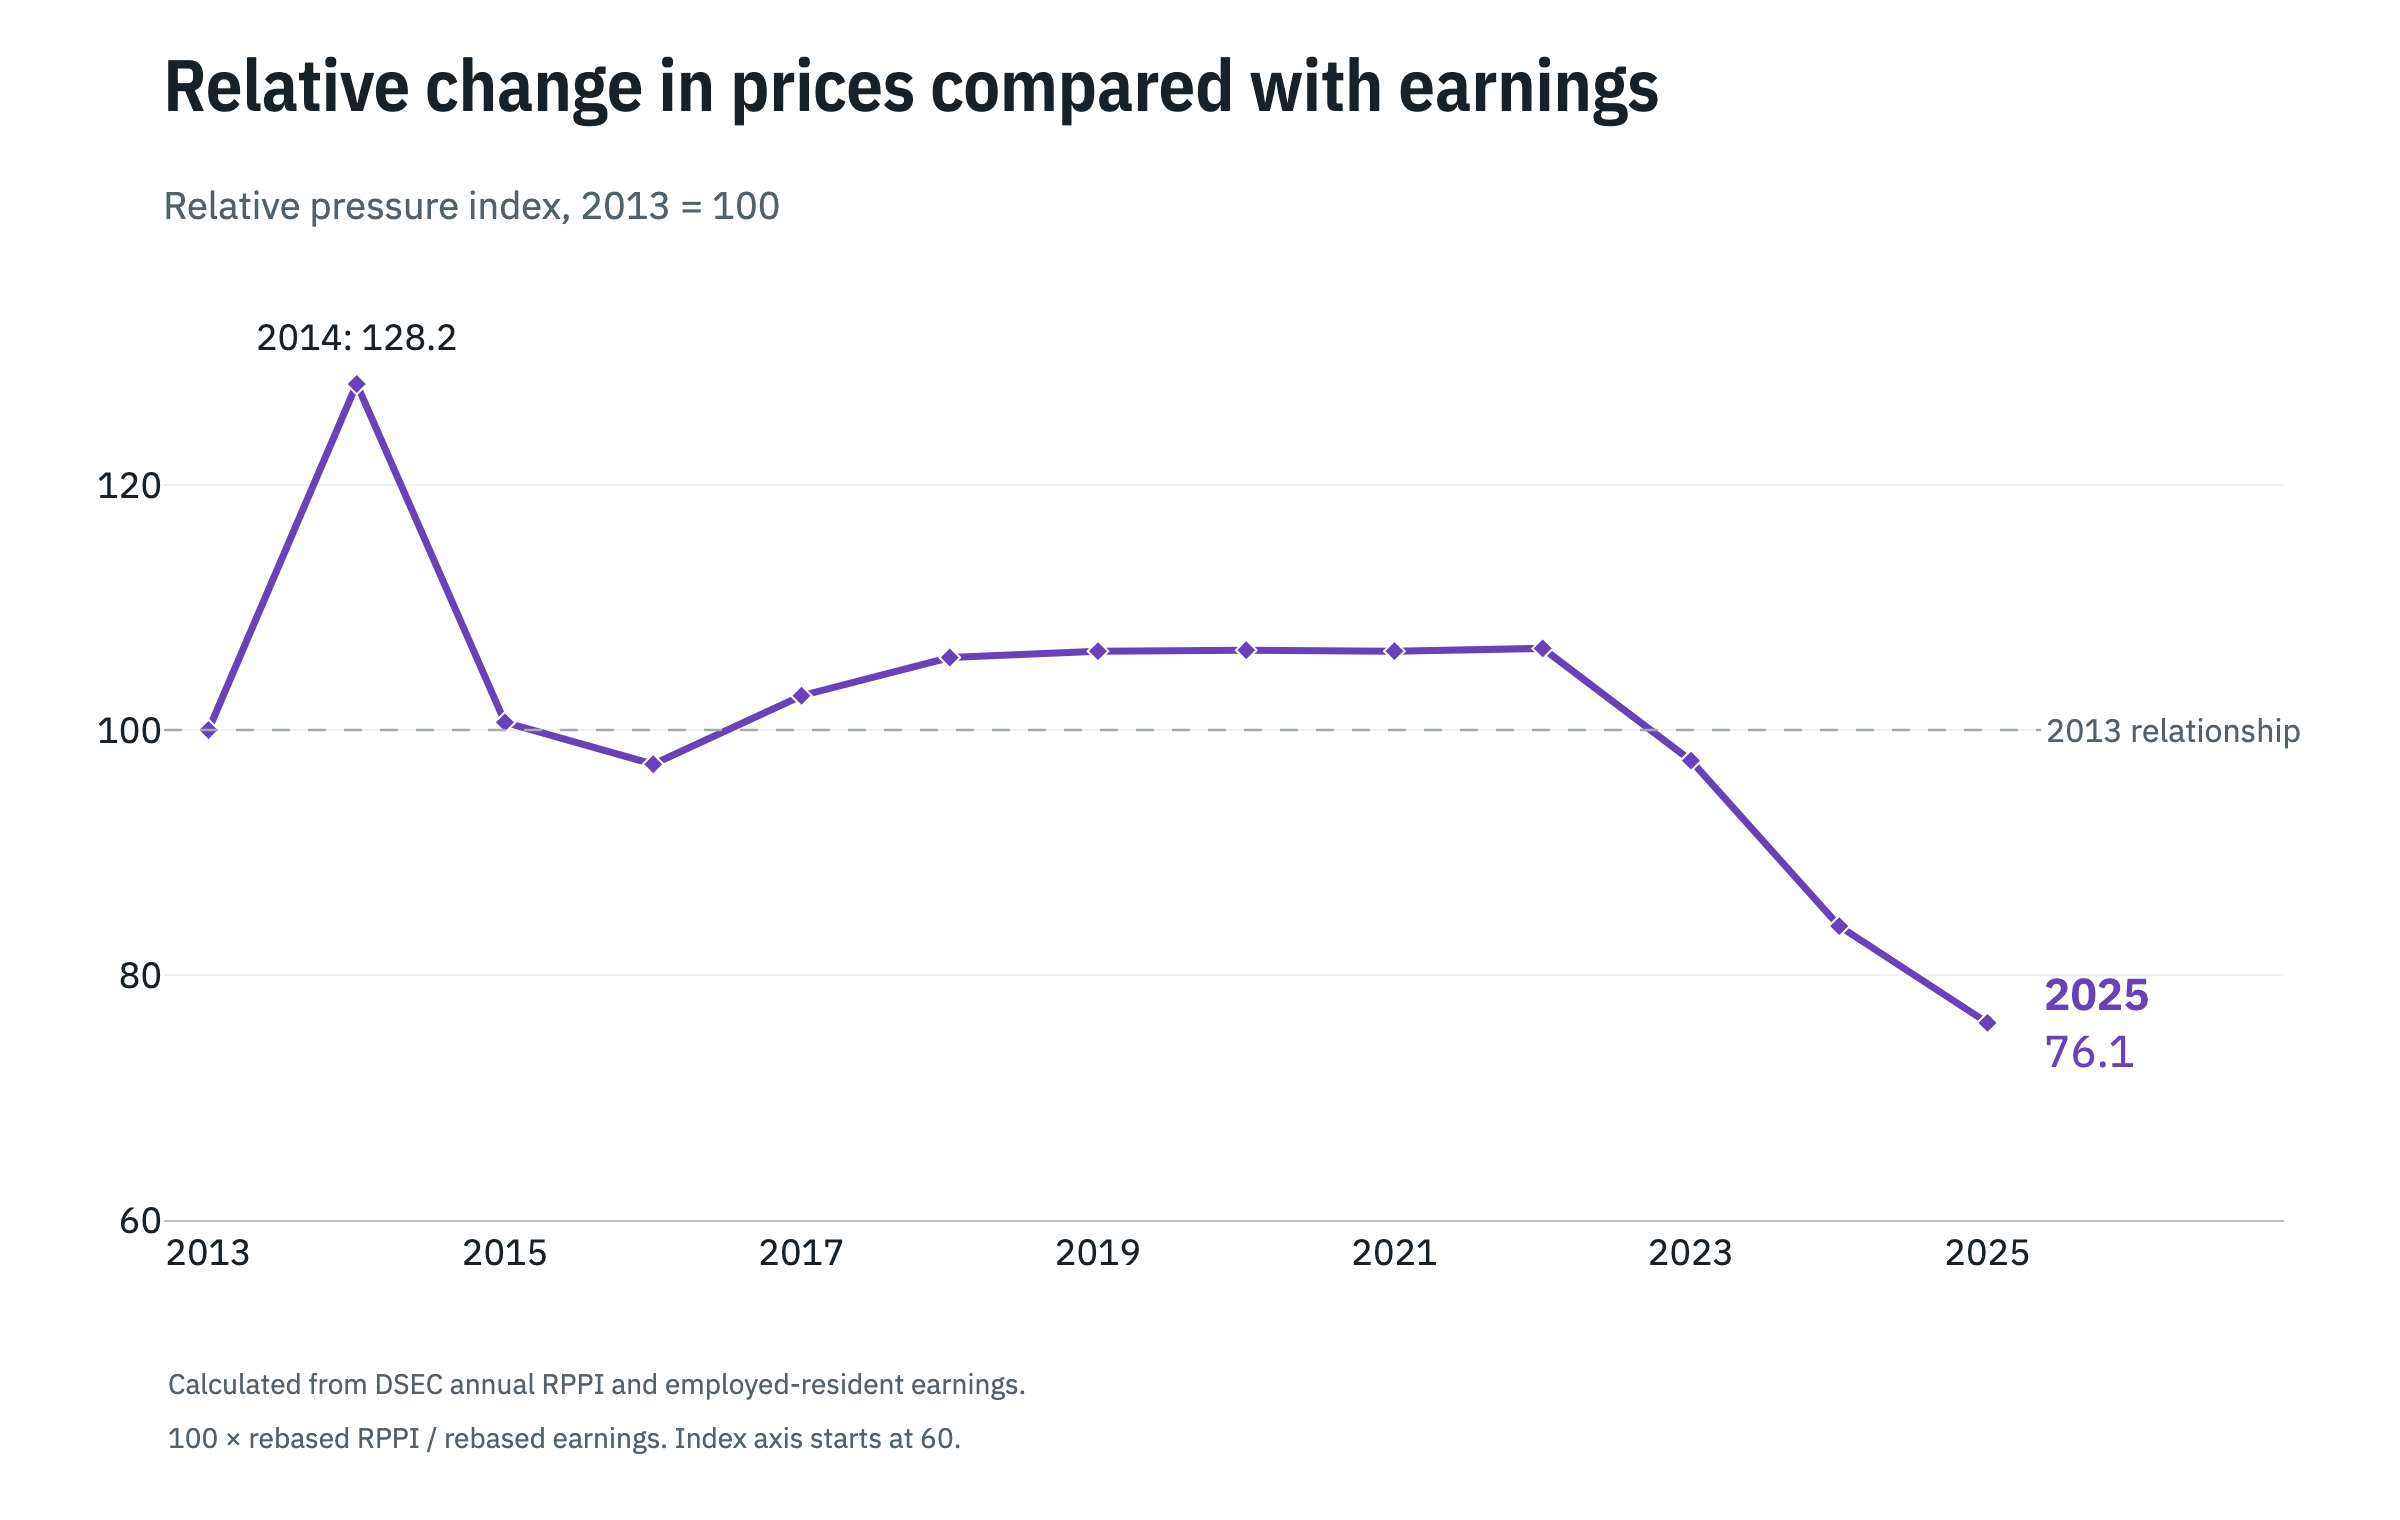

In [11]:
pressure = go.Figure(go.Scatter(x=data.year,y=data.relative_pressure_2013_100,mode='lines+markers',name='Relative pressure',
    line=dict(color=purple,width=3.5),marker=dict(color=purple,size=8,symbol='diamond',line=dict(color='white',width=1)),
    hovertemplate='%{x}<br>Relative pressure: %{y:.1f}<extra></extra>'))
chart_layout(pressure,'Relative change in prices compared with earnings','Relative pressure index, 2013 = 100',
    [2012.7,2027.0],[60,140],[60,80,100,120],[2013,2015,2017,2019,2021,2023,2025])
pressure.update_layout(showlegend=False)
pressure.add_hline(y=100,line_color='#A1ABB2',line_width=1.2,line_dash='dash')
pressure.add_annotation(x=2025.35,y=76.0897768552,text='<b>2025</b><br>76.1',showarrow=False,xanchor='left',
    align='left',font=dict(family=body_font,size=22,color=purple))
pressure.add_annotation(x=2014,y=128.2446808511,text='2014: 128.2',showarrow=False,yshift=24,font=dict(family=body_font,size=18,color=ink))
pressure.add_annotation(x=2025.35,y=100,text='2013 relationship',showarrow=False,xanchor='left',bgcolor='white',borderpad=2,font=dict(family=body_font,size=16,color=muted))
source_footer(pressure,'Calculated from DSEC annual RPPI and employed-resident earnings.',
    '100 × rebased RPPI / rebased earnings. Index axis starts at 60.')
export_chart(pressure,'03_relative_price_pressure',data[['year','relative_pressure_2013_100']],
    'Relative price pressure is 76.1 in 2025 with 2013 equal to 100. This compares changes since the base year and is not a household affordability ratio.')

## 7. Period comparisons
The full-period endpoints conceal different phases. Prices rise 42.0% from 2013 to 2020, then fall 26.8% from 2020 to 2025. Earnings rise 33.3% and 2.5% over those two periods. RPPI values in 2019–2021 are 266.8, 267.0 and 266.8: a near-flat plateau. The reported maximum of 267.0 in 2020 should not be given more precision or significance than these rounded observations support.

In [12]:
period_rows = []
periods = [(2013, 2014), (2013, 2018), (2013, 2020), (2014, 2025), (2018, 2025), (2019, 2021), (2020, 2025)]
for start, finish in periods:
    first = data.loc[data["year"].eq(start)].iloc[0]
    last = data.loc[data["year"].eq(finish)].iloc[0]
    price_change = 100 * (last["rppi_2011_100"] / first["rppi_2011_100"] - 1)
    earnings_change = 100 * (last["resident_earnings_mop"] / first["resident_earnings_mop"] - 1)
    pressure = 100 * (1 + price_change / 100) / (1 + earnings_change / 100)
    period_rows.append([start, finish, first["rppi_2011_100"], last["rppi_2011_100"], int(first["resident_earnings_mop"]), int(last["resident_earnings_mop"]), price_change, earnings_change, pressure])
period_columns = ["start_year", "end_year", "rppi_start", "rppi_end", "earnings_start_mop", "earnings_end_mop", "rppi_change_pct", "earnings_change_pct", "relative_pressure_end"]
period_comparisons = pd.DataFrame(period_rows, columns=period_columns)
period_comparisons.to_csv(folder / "period_comparisons.csv", index=False, float_format="%.10f")
display(period_comparisons[["start_year", "end_year", "rppi_change_pct", "earnings_change_pct", "relative_pressure_end"]].round(3))

,start_year,end_year,rppi_change_pct,earnings_change_pct,relative_pressure_end
0,2013,2014,28.245,0.000,128.245
1,2013,2018,41.223,33.333,105.918
2,2013,2020,42.021,33.333,106.516
3,2014,2025,-18.913,36.667,59.332
4,2018,2025,-26.365,2.500,71.839
5,2019,2021,0.000,0.000,100.000
6,2020,2025,-26.779,2.500,71.435


## 8. Sensitivity to the starting year
We check every earlier observed base year from 2013 through 2024, rather than selecting only favourable starting points. The endpoint is always 2025. The resulting relative-pressure index is below 100 for all 12 bases. It ranges from 59.3 for base 2014 to 90.6 for base 2024. For the illustrative bases 2013, 2014 and 2018, it is 76.1, 59.3 and 71.8.

These comparisons cover different lengths of time. Their magnitudes should not be treated as directly comparable annual rates. The sign of the endpoint comparison is consistent across the observed bases; the size depends on the chosen period. This check does not establish causation or complete housing affordability.

In [13]:
end = data.iloc[-1]
sensitivity_rows = []
for row in data.iloc[:-1].itertuples(index=False):
    price_change = 100 * (end["rppi_2011_100"] / row.rppi_2011_100 - 1)
    earnings_change = 100 * (end["resident_earnings_mop"] / row.resident_earnings_mop - 1)
    pressure = 100 * (1 + price_change / 100) / (1 + earnings_change / 100)
    sensitivity_rows.append([row.year, 2025, price_change, earnings_change, pressure])
sensitivity = pd.DataFrame(sensitivity_rows, columns=["base_year", "end_year", "rppi_change_pct", "earnings_change_pct", "relative_pressure_2025"])
assert len(sensitivity) == 12 and sensitivity["relative_pressure_2025"].lt(100).all()
sensitivity.to_csv(folder / "all_base_year_sensitivity.csv", index=False, float_format="%.10f")
display(sensitivity.round(3))

,base_year,end_year,rppi_change_pct,earnings_change_pct,relative_pressure_2025
0,2013,2025,3.989,36.667,76.090
1,2014,2025,-18.913,36.667,59.332
2,2015,2025,-13.877,13.889,75.621
3,2016,2025,-10.853,13.889,78.276
4,2017,2025,-20.139,7.895,74.018
5,2018,2025,-26.365,2.500,71.839
6,2019,2025,-26.724,2.500,71.489
7,2020,2025,-26.779,2.500,71.435
8,2021,2025,-26.724,2.500,71.489
9,2022,2025,-23.031,7.895,71.337


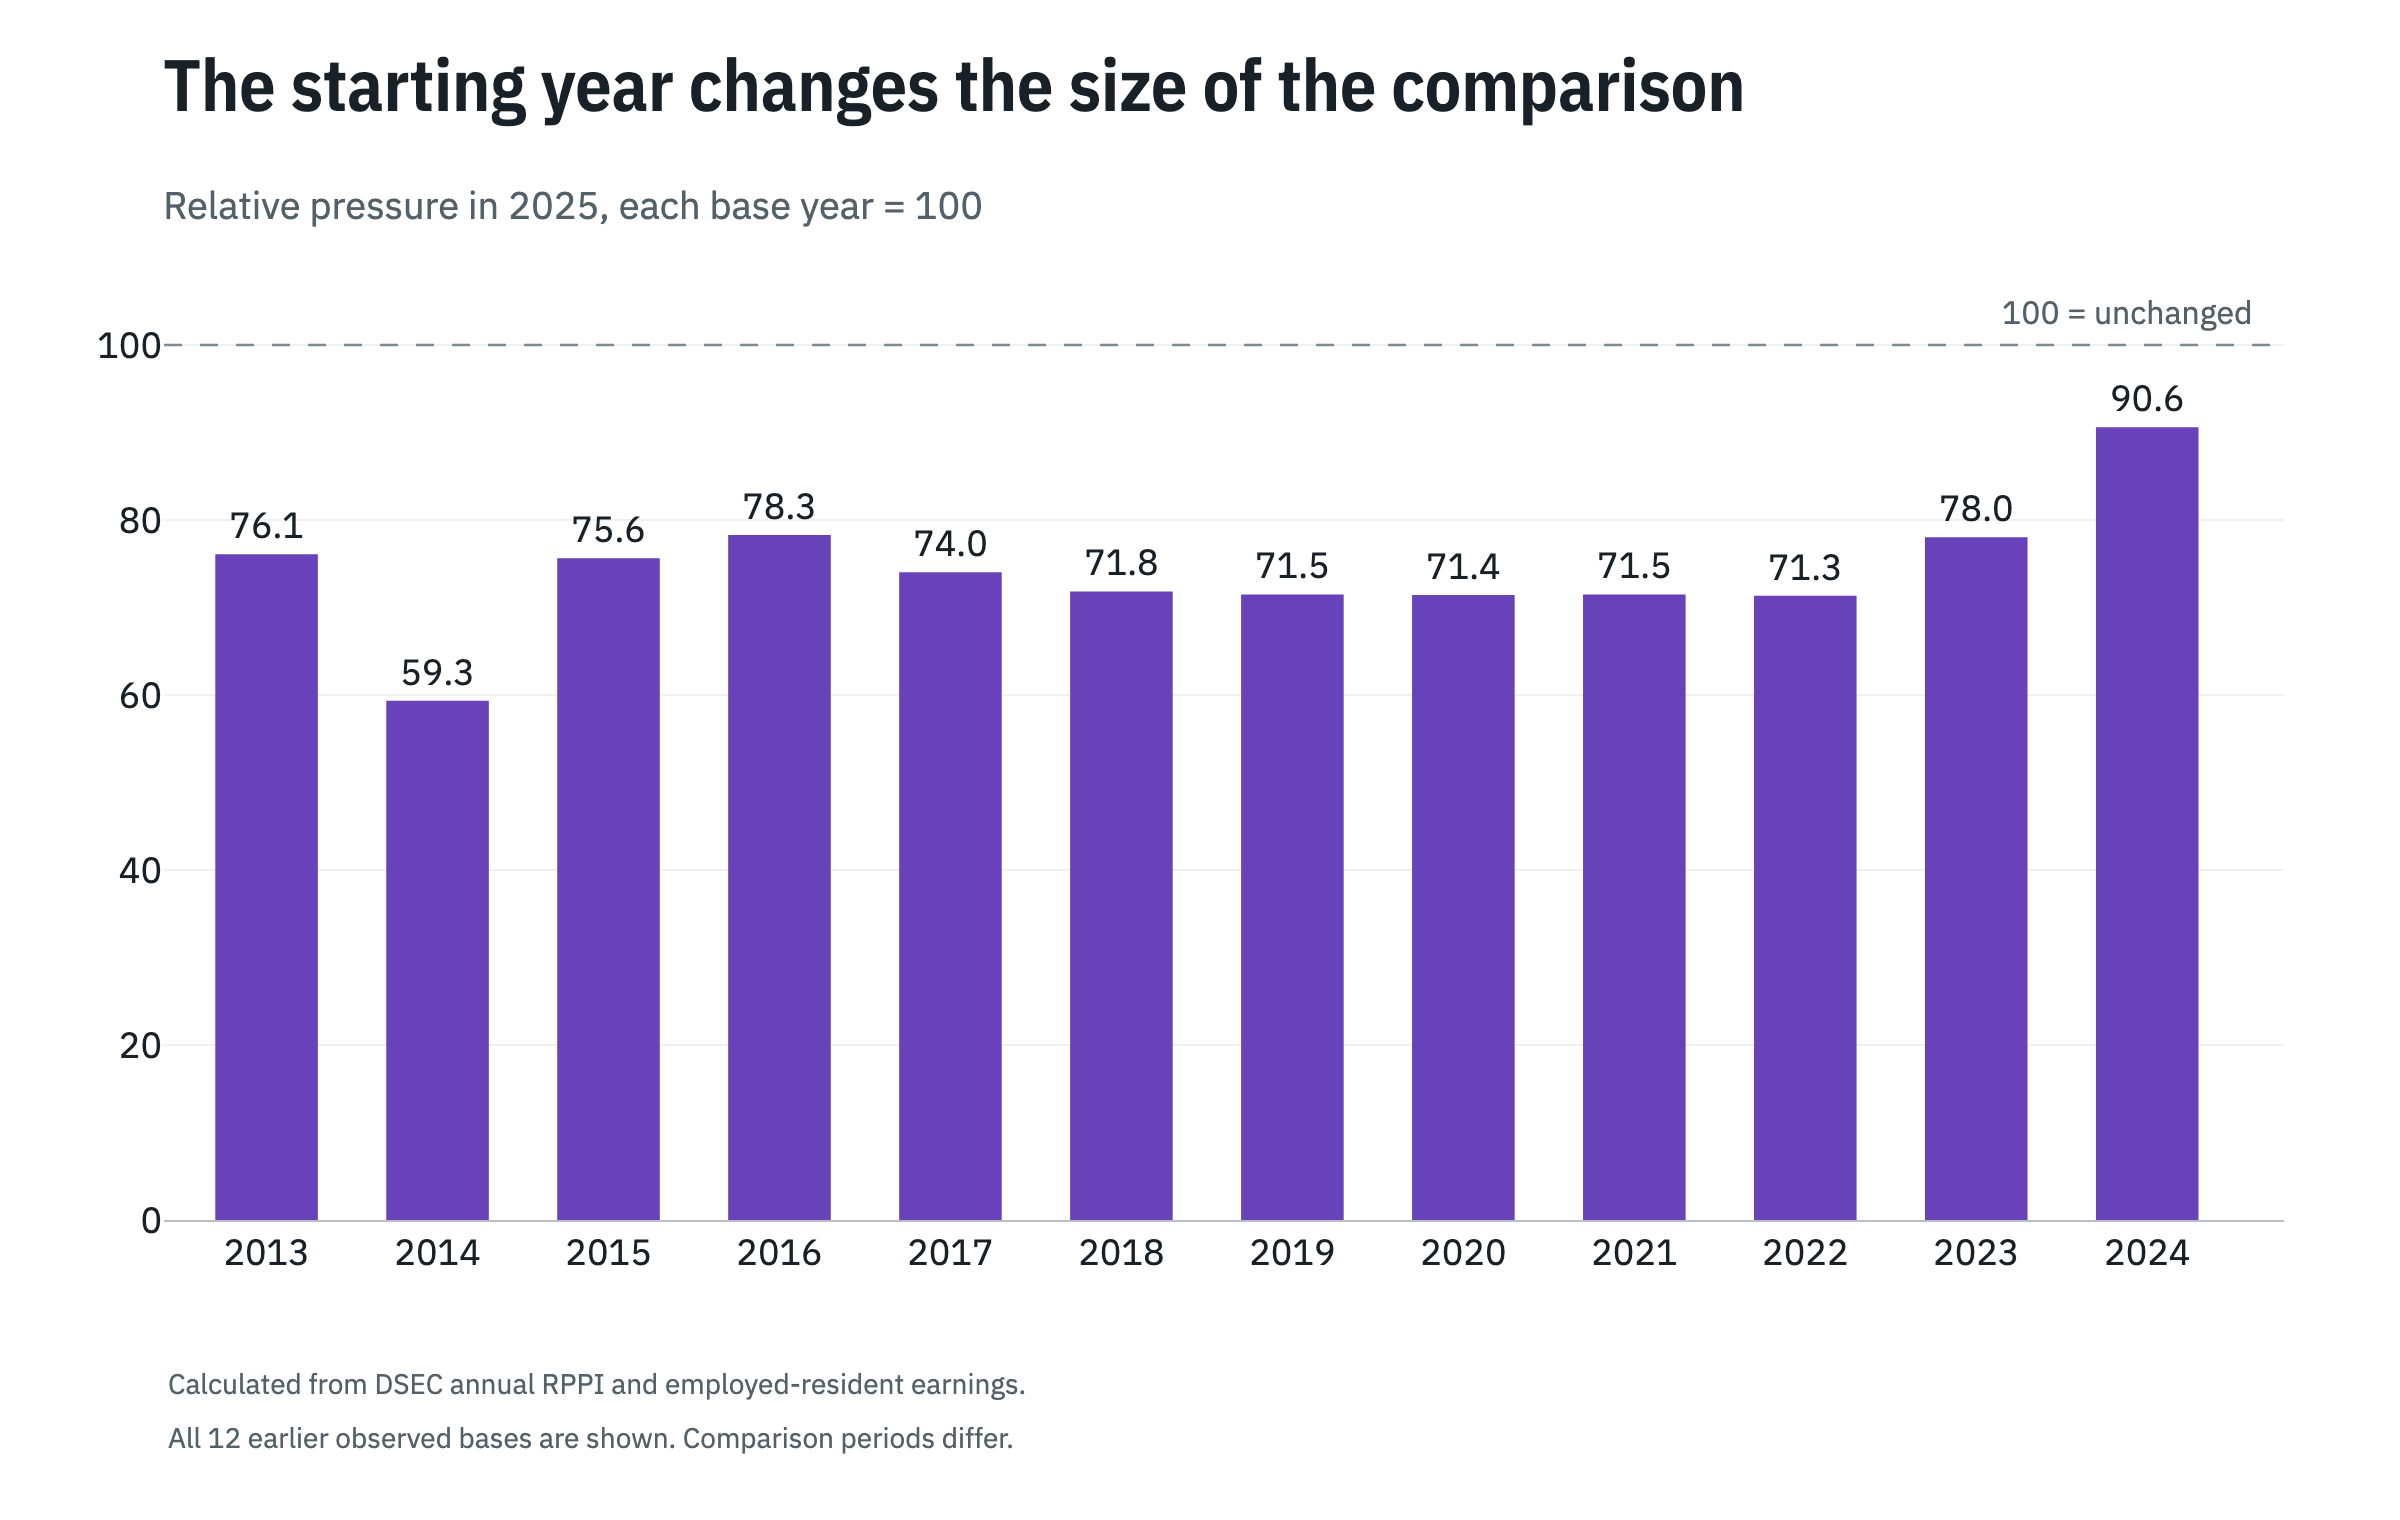

In [14]:
bases = go.Figure(go.Bar(x=sensitivity.base_year,y=sensitivity.relative_pressure_2025,name='Relative pressure in 2025',
    marker=dict(color=purple),width=0.60,text=sensitivity.relative_pressure_2025,texttemplate='%{text:.1f}',textposition='outside',
    textfont=dict(family=body_font,size=18,color=ink),hovertemplate='Base year %{x}<br>2025 pressure: %{y:.2f}<extra></extra>'))
chart_layout(bases,'The starting year changes the size of the comparison','Relative pressure in 2025, each base year = 100',
    [2012.4,2024.8],[0,112],[0,20,40,60,80,100],list(range(2013,2025)))
bases.update_layout(showlegend=False)
bases.add_hline(y=100,line_color='#7E8B93',line_width=1.2,line_dash='dash')
bases.add_annotation(x=2024.65,y=102,text='100 = unchanged',showarrow=False,xanchor='right',yshift=8,bgcolor='white',borderpad=2,font=dict(family=body_font,size=16,color=muted))
source_footer(bases,'Calculated from DSEC annual RPPI and employed-resident earnings.',
    'All 12 earlier observed bases are shown. Comparison periods differ.')
export_chart(bases,'04_all_base_year_sensitivity',sensitivity,
    'All 12 earlier observed base years give a 2025 pressure index below 100. The range is 59.3 for base 2014 to 90.6 for base 2024; the comparison periods differ.')

## 9. Final numerical results
All calculations use the saved published levels. The JSON file below is a compact result record used by the report and presentation.

In [15]:
last = data.iloc[-1]
peak = data.loc[data["rppi_2011_100"].idxmax()]
summary = {
    "first_year": 2013, "last_year": 2025, "annual_observations": len(data),
    "price_change_2013_2025_pct": float(last["price_index_2013_100"] - 100),
    "earnings_change_2013_2025_pct": float(last["earnings_index_2013_100"] - 100),
    "relative_pressure_2025_2013_base": float(last["relative_pressure_2013_100"]),
    "rppi_peak_year": int(peak["year"]), "rppi_peak_2011_base": float(peak["rppi_2011_100"]),
    "rppi_change_peak_to_2025_pct": float(100 * (last["rppi_2011_100"] / peak["rppi_2011_100"] - 1)),
    "database_observations_checked": len(checks), "database_exact_matches": len(checks),
    "source_register_entries": len(sources), "all_earlier_base_years_count": len(sensitivity),
    "all_earlier_bases_pressure_2025_below100": bool(sensitivity["relative_pressure_2025"].lt(100).all())
}
for base in [2014, 2018]:
    summary[f"relative_pressure_2025_{base}_base"] = float(sensitivity.loc[sensitivity["base_year"].eq(base), "relative_pressure_2025"].item())
for start, finish in [(2013, 2020), (2018, 2025)]:
    row = period_comparisons.loc[period_comparisons["start_year"].eq(start) & period_comparisons["end_year"].eq(finish)].iloc[0]
    summary[f"price_change_{start}_{finish}_pct"] = float(row["rppi_change_pct"])
    summary[f"earnings_change_{start}_{finish}_pct"] = float(row["earnings_change_pct"])
for label, position in [("lowest", sensitivity["relative_pressure_2025"].idxmin()), ("highest", sensitivity["relative_pressure_2025"].idxmax())]:
    summary[f"{label}_pressure_base_year"] = int(sensitivity.loc[position, "base_year"])
    summary[f"{label}_pressure_index"] = float(sensitivity.loc[position, "relative_pressure_2025"])
for column, prefix in [("rppi_growth_pct", "rppi"), ("earnings_growth_pct", "earnings")]:
    for label, position in [("rise", data[column].idxmax()), ("fall", data[column].idxmin())]:
        summary[f"largest_{prefix}_annual_{label}_year"] = int(data.loc[position, "year"])
        summary[f"largest_{prefix}_annual_{label}_pct"] = float(data.loc[position, column])
plateau = data.loc[data["year"].between(2019, 2021), "rppi_2011_100"]
summary["rppi_2019_2021_max_minus_min_points"] = float(plateau.max() - plateau.min())
(folder / "summary_metrics.json").write_text(json.dumps(summary, indent=2))
display(pd.Series(summary).to_frame("Value"))

,Value
first_year,2013
last_year,2025
annual_observations,13
price_change_2013_2025_pct,3.989362
earnings_change_2013_2025_pct,36.666667
relative_pressure_2025_2013_base,76.089777
rppi_peak_year,2020
rppi_peak_2011_base,267.0
rppi_change_peak_to_2025_pct,-26.779026
database_observations_checked,26


## Findings and limits
From 2013 to 2025, RPPI rises 4.0% and the annual employed-resident earnings median rises 36.7%. This endpoint comparison conceals a large early price rise, a near-flat 2019–2021 period and later price falls. From 2018 to 2025, prices fall 26.4% while earnings rise 2.5%. The direction of the 2025 endpoint comparison holds for every earlier base in the observed sample.

The results do not explain why prices or earnings changed. Thirteen annual aggregate observations are not independent household records. Earnings medians can change when the composition of employment changes; the 2015 increase does not imply a 20% pay rise for every resident. The official 2015 publication confirms the reported median and survey scope but does not establish the cause of that change.

The 2017 pricing-model change remains a historical comparability limit even though all values match DSEC's current series. The post-2018 comparison avoids that transition. Both series are nominal. Household income, savings, deposits, mortgage interest rates, housing quality and income distribution are outside this project. Relative pressure is not a complete affordability measure.

The annual Employment Survey includes precision information for some overall-population statistics. Its overall earnings-median precision cannot be transferred to the employed-resident median used here. We do not have a matched set of resident-median uncertainty estimates for all 13 years, so no confidence interval or error bar is invented. No causal model, forecast, significance test or unsupported correlation claim is made.

## Reproducibility
The notebook starts with separate source tables, validates their join, verifies 18 saved source hashes and matches all 26 annual values against the saved current-database response. It checks coverage, duplicate years, missing and nonpositive levels, the common base and growth gaps. It regenerates the joined CSV, period and sensitivity tables, four figures, metrics and software versions. `rerun_notebook.py` uses relative paths. Exact project `pyproject.toml` and `uv.lock` copies are in `environment/`. The original publications remain unchanged.

All six team members share the agreed responsibilities for Python, visualization and interpretation. This notebook does not infer who typed a cell, held a meeting or completed an individual peer review.

In [16]:
versions = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__}
(folder / "software_versions.json").write_text(json.dumps(versions, indent=2))
print("Saved the joined table, summary metrics, software versions and four PNG/PDF figures.")
print("No observations were removed, interpolated or replaced with quarterly estimates.")

import importlib.metadata
visual_versions = {'python':platform.python_version(),'plotly':plotly.__version__,
    'kaleido':importlib.metadata.version('kaleido'),'fonts':'IBM Plex Sans and Sans Condensed, bundled OFL files',
    'palette':{'prices':purple,'earnings':teal,'ink':ink,'grid':grid},'smoothing':False,'dual_axes':False}
(folder/'visual_export_versions.json').write_text(json.dumps(visual_versions,indent=2))
print('Saved four redesigned charts, report variants, Plotly specifications and offline interactive HTML.')


Saved the joined table, summary metrics, software versions and four PNG/PDF figures.
No observations were removed, interpolated or replaced with quarterly estimates.
Saved four redesigned charts, report variants, Plotly specifications and offline interactive HTML.
